# Classification Supervised Model on Student Depression

Question: Which demographic, academic, social, economic, and health-related factors are most associated with depression among students?

Stakeholder: University counseling center

In [12]:
#Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [13]:
#Prepping the dataset:

df = pd.read_csv('Student_Depression_Dataset.csv')

#Checking if there are missing values in the columns:
print(df.isna().sum().sort_values(ascending=False).head(20))

# Checking for duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())

#Checking the data types:
print("\nData types:")
print(df.dtypes)

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

Number of duplicate rows: 0

Data types:
Gender                  object
Age                      int64
Family_background       object
Relationship_status     object
Marital_status          object
Living_style            object
Current_semester         int64
CGPA                   float64
friend_circle           object
Health_condition        object
Cost_without_study       int64
Home_division           object
Depression              object
dtype: object


In [14]:
#Encoding the target variable:

#Target variable: Depression (Yes/No)
print(df["Depression"].unique())
print(df["Depression"].dtype)

#Encoding Depression
df["Depression"] = df["Depression"].str.strip().map({
    "No": 0,
    "Yes": 1
})

['Yes' 'No']
object


In [15]:
#Checking the Depression encoding
print(df["Depression"].value_counts())

Depression
0    3263
1    1201
Name: count, dtype: int64


In [16]:
#Getting rid of whitespaces in categorical variables

categorical_cols = [
    "Gender",
    "Family_background",
    "Relationship_status",
    "Marital_status",
    "Living_style",
    "friend_circle",
    "Health_condition",
    "Home_division"
]

for col in categorical_cols:
    df[col] = df[col].astype(str).str.strip()

In [17]:
#Separating the independent variables and the target variable

# Independent variables
X = df.drop("Depression", axis=1)

# Target variable
y = df["Depression"]

In [18]:
#Encoding categorical variables
X = pd.get_dummies(
    X,
    columns=[
        "Gender",
        "Family_background",
        "Relationship_status",
        "Marital_status",
        "Living_style",
        "friend_circle",
        "Health_condition",
        "Home_division"
    ],
    drop_first=True,
    dtype=int
)


In [28]:
X.head()

,Age,Current_semester,CGPA,Cost_without_study,Gender_Male,Family_background_Middle class,Family_background_Rich class,Relationship_status_In a Relationship,Relationship_status_Single,Marital_status_Separated,...,Health_condition_Critical,Health_condition_Good,Health_condition_Normal,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet
0,22,8,3.43,10113,0,1,0,0,1,0,...,1,0,0,1,0,0,0,0,0,0
1,19,2,3.70,13815,1,1,0,0,1,0,...,0,0,0,1,0,0,0,0,0,0
2,23,8,3.28,15450,1,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
3,20,2,3.77,17413,1,1,0,0,0,0,...,0,1,0,0,1,0,0,0,0,0
4,21,1,4.00,16693,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


In [20]:
#Training and testing data:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [21]:
#Random Forest model
model = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=200,
                       random_state=42)

In [22]:
#Making predictions:
y_pred = model.predict(X_test)

Model Accuracy: 0.9888017917133258

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       653
           1       1.00      0.96      0.98       240

    accuracy                           0.99       893
   macro avg       0.99      0.98      0.99       893
weighted avg       0.99      0.99      0.99       893



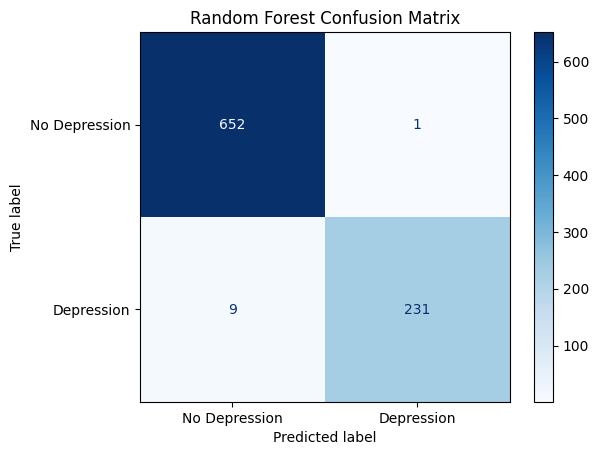

In [59]:
#Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

#Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

#Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Depression", "Depression"]
)

disp.plot(cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.show()


Five Incorrect Predictions:
      Age  Current_semester  CGPA  Cost_without_study  Gender_Male  \
295    23                 5  3.00                6505            1   
4436   22                 4  2.89                9887            1   
1367   23                 7  3.48               19549            0   
1117   26                10  3.00                5141            1   
3687   20                 3  2.30               26000            0   
3528   28                 9  3.09               16000            0   
4454   23                10  2.68                2630            0   
2654   23                 7  2.99                7900            1   
2561   27                 7  3.47               12030            0   
3094   26                 2  3.12                7400            1   

      Family_background_Middle class  Family_background_Rich class  \
295                                0                             0   
4436                               0                        

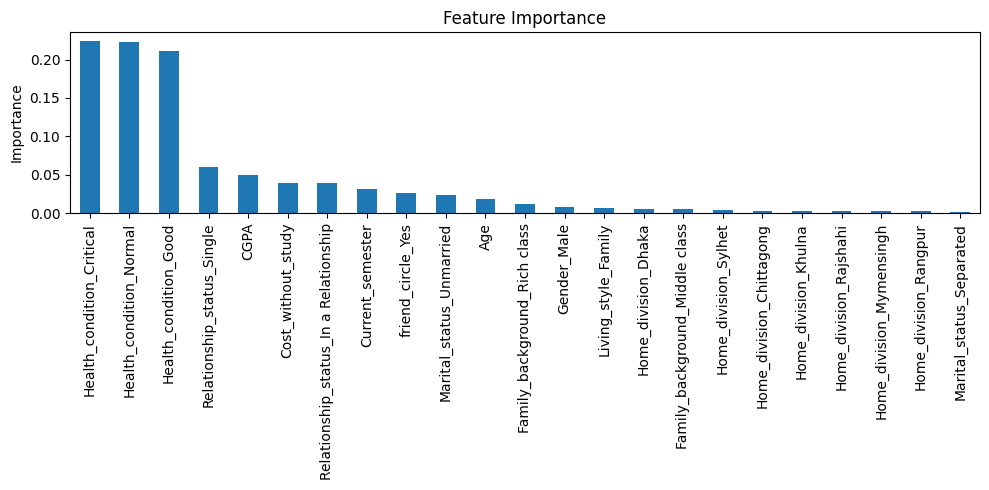

In [57]:
#Incorrect predictions
results = X_test.copy()
results["Actual"] = y_test
results["Predicted"] = y_pred

incorrect = results[
    results["Actual"] != results["Predicted"]
]

print("\nFive Incorrect Predictions:")
print(incorrect.head(10))

# Feature importance
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nFeature Importance:")
print(importance)

importance.plot(
    kind="bar",
    figsize=(10, 5),
    title="Feature Importance"
)

plt.ylabel("Importance")
plt.tight_layout()
plt.show()

In [58]:

import pandas as pd
from IPython.display import display

false_positives = incorrect[incorrect["Actual"] == 0]
false_negatives = incorrect[incorrect["Actual"] == 1]

#Selecting 1 false positive and 4 false negatives
selected_samples = pd.concat([
    false_positives.head(1),
    false_negatives.head(4)
])

#Remove Home_division
error_table = selected_samples.drop(
    columns=[
        col for col in selected_samples.columns
        if "Home_division" in col
    ]
).copy()

#Error type
error_table["Error_Type"] = error_table.apply(
    lambda row: "False Positive" if row["Actual"] == 0
    else "False Negative",
    axis=1
)


error_table["Actual"] = error_table["Actual"].map({
    0: "No Depression",
    1: "Depression"
})

error_table["Predicted"] = error_table["Predicted"].map({
    0: "No Depression",
    1: "Depression"
})

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

display(error_table)


,Age,Current_semester,CGPA,Cost_without_study,Gender_Male,Family_background_Middle class,Family_background_Rich class,Relationship_status_In a Relationship,Relationship_status_Single,Marital_status_Separated,Marital_status_Unmarried,Living_style_Family,friend_circle_Yes,Health_condition_Critical,Health_condition_Good,Health_condition_Normal,Actual,Predicted,Error_Type
3094,26,2,3.12,7400,1,0,1,0,1,0,1,1,1,0,0,0,No Depression,Depression,False Positive
295,23,5,3.00,6505,1,0,0,0,1,0,1,0,0,0,0,1,Depression,No Depression,False Negative
4436,22,4,2.89,9887,1,0,0,0,1,1,0,0,0,0,0,1,Depression,No Depression,False Negative
1367,23,7,3.48,19549,0,1,0,0,1,0,1,0,0,0,0,1,Depression,No Depression,False Negative
1117,26,10,3.00,5141,1,0,0,0,1,0,1,0,0,0,0,1,Depression,No Depression,False Negative


To answer the question, I'm going to group the features into five main categories to see which is more important in the model.

Feature Importance by Category:
Health-related    65.851470
Social            15.044641
Academic           8.000447
Economic           5.605017
Demographic        2.659453
dtype: float64


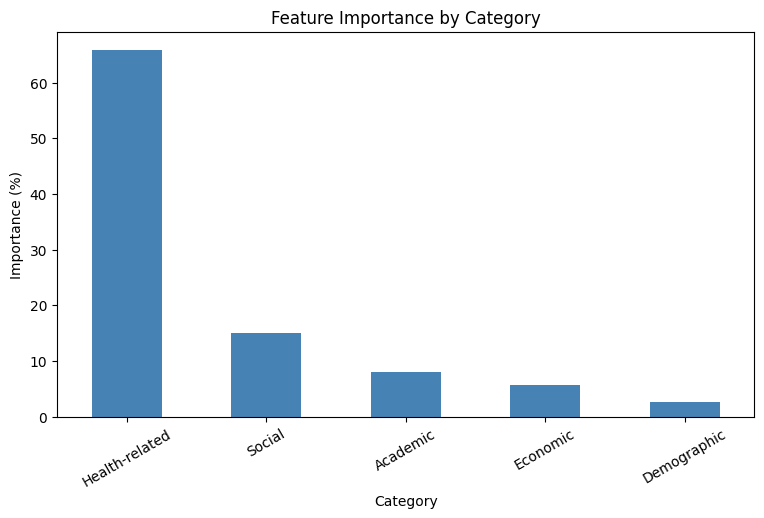

In [35]:
#Grouping features

feature_groups = {
    "Demographic": ["Age","Gender_Male"],

    "Academic": ["CGPA","Current_semester"],

    "Social": [
        col for col in X.columns
        if any(term in col for term in ["Relationship_status","Marital_status","friend_circle"])
    ],

    "Economic": ["Cost_without_study"] + [
        col for col in X.columns
        if "Family_background" in col
    ],

    "Health-related": [
        col for col in X.columns
        if "Health_condition" in col
    ]
}

#total importance for each category

category_importance = {}

for category, features in feature_groups.items():
    category_importance[category] = importance[importance.index.isin(features)].sum()

#Converting to percentage
category_importance = pd.Series(category_importance).sort_values(ascending=False) * 100

print("Feature Importance by Category:")
print(category_importance)


category_importance.plot(
    kind="bar",
    figsize=(9, 5),
    color="steelblue",
    title="Feature Importance by Category"
)

plt.ylabel("Importance (%)")
plt.xlabel("Category")
plt.xticks(rotation=30)
plt.show()
